# Chapter 12: Natural Experiments: Before and After, Twins, and the Line

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Natural Experiments: Before and After, Twins, and the Line](https://books.sugiv.fyi/lift/natural-experiments.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import quasi as Q, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


P = Q.country_panel()
P["treat"] = P.brazil * P.post
brazil = P[P.brazil == 1]
before_after = brazil[brazil.post == 1].active_share.mean() - brazil[brazil.post == 0].active_share.mean()
did = smf.ols("active_share ~ treat + C(country) + C(week)", P).fit(
    cov_type="cluster", cov_kwds={"groups": P.country.astype("category").cat.codes})
y_br, y_syn, w_syn = Q.synth_path(P)
synth_effect = (y_br - y_syn)[Q.LAUNCH_WEEK:].mean()
glue_num("ba", before_after)
glue_num("did", did.params["treat"])
glue_num("syn", synth_effect)
glue_num("truth", Q.OFFLINE_EFFECT)

Here's the finding first. Parlo launched **Offline Mode** in Brazil only, through a deal with a Brazilian phone carrier. No randomisation was possible: a whole country got the feature on one day. Three analyses of the same data give three answers:

| Method | Offline Mode's effect on weekly active share |
|---|---|
| Brazil, before vs after | +3.2 points |
| Difference-in-differences against all other countries | +3.7 points |
| Synthetic control: Brazil vs a weighted "twin" built from other countries | +1.6 points |

The true effect in the simulator is **+1.5 points**. Only synthetic control gets close. The textbook method, difference-in-differences, does *worse* than the naive before/after comparison, because its key assumption fails here, and a plot you should always draw shows it failing.

This chapter covers three natural experiments: situations where the rollout itself creates a comparison. Each comes with the assumption it rests on and the check that tests it. The agent example is my favourite: **any threshold in an agent pipeline is a free experiment.**

> **Note**
>
> The numbers come from `lift/sim/quasi.py`: a weekly panel of 14 countries with shared seasons and country-specific growth trends, and a log of Juno lessons with an LLM judge's score and a rewrite rule.

## Before and after: what else changed?

The simplest comparison is Brazil after the launch against Brazil before. It's wrong whenever anything else changed at the same time, and something always does. Here every country follows the same seasons (a January rush, a summer slump, a September return), and Brazil was also **growing**: its active share was rising by about a tenth of a point a week before Offline Mode existed. Before/after credits all of that to the feature.

## Difference-in-differences: subtract the other countries

**Difference-in-differences (DiD)** uses the other countries as a control for "what else changed". Brazil's before/after change, minus the other countries' before/after change, removes anything that hit everyone, like the seasons. In regression form, with a fixed effect for each country and each week:

In [3]:
did = smf.ols("active_share ~ treat + C(country) + C(week)", P).fit(
    cov_type="cluster", cov_kwds={"groups": P.country.astype("category").cat.codes})
print(f"DiD estimate: {did.params['treat']:.2f} points (standard error {did.bse['treat']:.2f})")

DiD estimate: 3.72 points (standard error 0.38)


The standard errors are **clustered by country**, because weeks from the same country aren't independent. That's Chapter 2's "count the unit you randomised" again: here the unit is a country, and there are only 14.

DiD rests on one assumption: **parallel trends**. Without the launch, Brazil would have moved in parallel with the other countries. You can't check that after the launch, but you can check it *before*. An **event study** estimates the Brazil-vs-others gap week by week, relative to the week before launch. Before launch, those gaps should hover around zero:

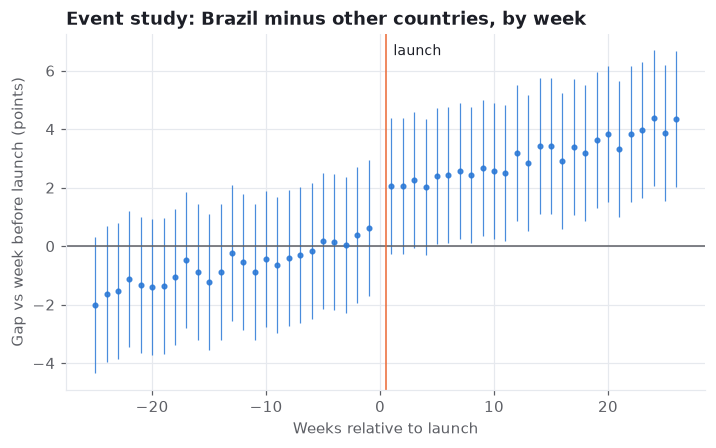

In [4]:
E = P.copy()
E["rel"] = E.week - (Q.LAUNCH_WEEK - 1)
for r in sorted(E.rel.unique()):
    if r != 0:
        E[f"b_{r + 100}"] = ((E.brazil == 1) & (E.rel == r)).astype(int)
terms = " + ".join(c for c in E.columns if c.startswith("b_"))
ev = smf.ols(f"active_share ~ {terms} + C(country) + C(week)", E).fit()
rel = np.array([int(c[2:]) - 100 for c in E.columns if c.startswith("b_")])
coef = np.array([ev.params[f"b_{r + 100}"] for r in rel])
se = np.array([ev.bse[f"b_{r + 100}"] for r in rel])
order = np.argsort(rel)
rel, coef, se = rel[order], coef[order], se[order]

fig, ax = plt.subplots()
ax.errorbar(rel, coef, yerr=1.96 * se, fmt="o", markersize=3, color=style.SERIES[0],
            ecolor=style.SERIES[0], elinewidth=0.8, alpha=0.85)
ax.axhline(0, color=style.MUTED, linewidth=1)
ax.axvline(0.5, color=style.SERIES[1], linewidth=1)
ax.annotate("launch", xy=(0.5, ax.get_ylim()[1] * 0.9), xytext=(5, 0), textcoords="offset points",
            fontsize=9, color=style.INK)
ax.set(title="Event study: Brazil minus other countries, by week",
       xlabel="Weeks relative to launch", ylabel="Gap vs week before launch (points)")
plt.show()

Each week's estimate is noisy, but the pattern isn't: the gap climbs steadily for half a year *before* the launch. That's a failed parallel-trends check. Brazil was growing faster than the average country, DiD reads the continued growth after launch as the feature's effect, and the estimate more than doubles. Before/after happened to do better only because the seasons partly offset the trend: two errors cancelling, which you can't rely on.

When the event study shows a pre-trend, don't report the DiD number. Find better controls.

## Synthetic control: build Brazil a twin

If no single country moves like Brazil, perhaps a **blend** of countries does. **Synthetic control** (Abadie et al., 2010) finds non-negative weights, summing to one, that make a weighted average of other countries track Brazil as closely as possible *before* the launch. After the launch, that twin shows what Brazil would have done without Offline Mode.

In [5]:
y_br, y_syn, w_syn = Q.synth_path(P)
w_syn[w_syn > 0.01].sort_values(ascending=False).round(2).to_frame("weight in Brazil's twin")

,weight in Brazil's twin
Mexico,0.54
India,0.34
Turkey,0.10
Japan,0.02


The twin is mostly made of other fast-growing markets. I fit it on each country's path *relative to its own pre-launch average*, so the twin has to match Brazil's shape (seasons and growth) rather than its level. Here's Brazil against its twin:

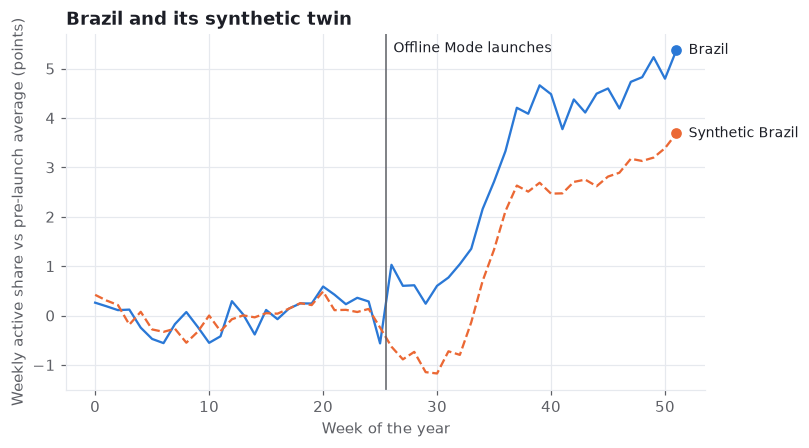

In [6]:
weeks = y_br.index.values
fig, ax = plt.subplots()
ax.plot(weeks, y_br.values, color=style.SERIES[0], linewidth=1.5)
ax.plot(weeks, y_syn.values, color=style.SERIES[1], linewidth=1.5, linestyle="--")
style.label_line_end(ax, weeks[-1], y_br.values[-1], "Brazil", style.SERIES[0])
style.label_line_end(ax, weeks[-1], y_syn.values[-1], "Synthetic Brazil", style.SERIES[1])
ax.axvline(Q.LAUNCH_WEEK - 0.5, color=style.MUTED, linewidth=1)
ax.annotate("Offline Mode launches", xy=(Q.LAUNCH_WEEK - 0.5, ax.get_ylim()[1]), xytext=(5, -12),
            textcoords="offset points", fontsize=9, color=style.INK)
ax.set(title="Brazil and its synthetic twin",
       xlabel="Week of the year", ylabel="Weekly active share vs pre-launch average (points)")
plt.show()

In [7]:
pre_rmse = np.sqrt(((y_br - y_syn)[: Q.LAUNCH_WEEK] ** 2).mean())
glue_num("pre_rmse", pre_rmse)

Before the launch the twin tracks Brazil to within about 0.25 points a week, which is the weekly noise. After it, Brazil pulls away by about 1.6 points, close to the truth.

How do you know that gap isn't luck? With one treated country there's no standard error in the usual sense. Instead, run a **placebo test**: pretend each other country got Offline Mode, build *its* twin, and see how big its post-launch gap is compared with its pre-launch fit. If Brazil's ratio is the most extreme, that's evidence:

In [8]:
def gap_ratio(country):
    # Placebo twins are built without Brazil, the one country that really was treated.
    panel = P if country == "Brazil" else P[P.country != "Brazil"]
    y, syn, _ = Q.synth_path(panel, treated=country)
    gap = y - syn
    return np.sqrt((gap[Q.LAUNCH_WEEK:] ** 2).mean()) / np.sqrt((gap[: Q.LAUNCH_WEEK] ** 2).mean())


ratios = pd.Series({c: gap_ratio(c) for c in Q.COUNTRIES}).sort_values(ascending=False)
ratios.round(1).head(5).to_frame("post-launch gap / pre-launch fit")

,post-launch gap / pre-launch fit
Brazil,6.4
Mexico,3.0
Germany,2.1
France,2.0
Korea,1.8


In [9]:
glue_num("br_ratio", ratios["Brazil"])
glue_num("next_ratio", ratios.drop("Brazil").max())
glue_num("rank_p", 1 / len(ratios))

Brazil's ratio, 6.4, is far above every placebo (the next largest is 3.0). Brazil ranks first of 14, so if Offline Mode had done nothing, a result this extreme would happen by chance about one time in 14: a p-value of about 0.07. That's the smallest p-value 14 countries can give, which is the honest limit of a one-country launch.

Synthetic control needs a good pre-launch fit, a pool of untreated units that can combine into the treated one, and no other shock that hit only the treated unit at launch time. (If the carrier deal also came with a TV campaign in Brazil, no method can separate the two.)

## Regression discontinuity: every threshold is an experiment

Now Juno. Each of Juno's tutoring answers is scored by an LLM judge between 0 and 1. If the score is **below 0.5**, a larger, slower model rewrites the answer before the learner sees it. Juno's team wants to know: does rewriting help? It costs money and latency, and they're considering raising the threshold.

The naive comparison says rewriting hurts:

In [10]:
R = Q.rewrite_log()
R.groupby(R.rewritten.map({0: "kept", 1: "rewritten"})).agg(
    lessons=("completed", "size"), completion=("completed", "mean"), mean_score=("judge_score", "mean"))

,lessons,completion,mean_score
rewritten,,,
kept,92516,0.605,0.693
rewritten,27484,0.495,0.396


Of course it does: answers get rewritten *because* they were poor, often in hard lessons. But look closely at the threshold. An answer scored 0.49 and one scored 0.51 are, for practical purposes, the same quality. One was rewritten and the other wasn't, for no reason other than which side of the line it fell on. Near the cutoff, the threshold acts like a coin flip. That's a **regression discontinuity** (Imbens and Lemieux, 2008).

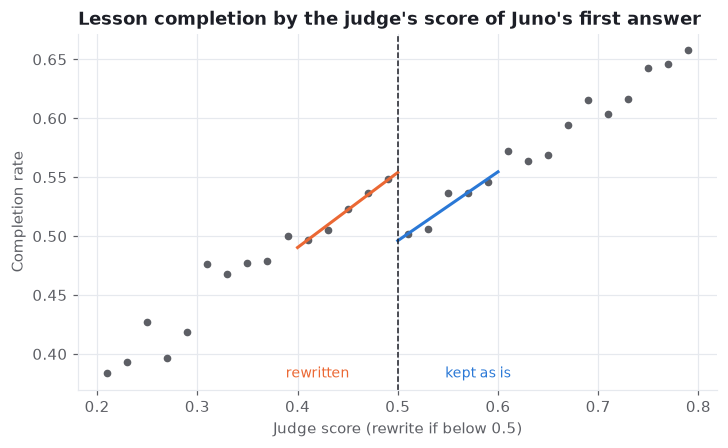

In [11]:
bins = np.linspace(0.2, 0.8, 31)
mid = (bins[:-1] + bins[1:]) / 2
binned = R.groupby(pd.cut(R.judge_score, bins), observed=False).completed.mean().values
h = 0.1
near = R[(R.judge_score - Q.CUTOFF).abs() < h].assign(x=lambda d: d.judge_score - Q.CUTOFF)
fit = smf.ols("completed ~ rewritten * x", near).fit(cov_type="HC1")

fig, ax = plt.subplots()
ax.plot(mid, binned, "o", color=style.MUTED, markersize=4)
for side, colour in [(1, style.SERIES[1]), (0, style.SERIES[0])]:
    xs = np.linspace(-h, 0, 20) if side == 1 else np.linspace(0, h, 20)
    ys = fit.predict(pd.DataFrame({"x": xs, "rewritten": side}))
    ax.plot(xs + Q.CUTOFF, ys, color=colour, linewidth=2)
ax.axvline(Q.CUTOFF, color=style.INK, linewidth=1, linestyle="--")
ax.annotate("rewritten", xy=(0.42, ax.get_ylim()[0]), xytext=(0, 8), textcoords="offset points",
            ha="center", fontsize=9, color=style.SERIES[1])
ax.annotate("kept as is", xy=(0.58, ax.get_ylim()[0]), xytext=(0, 8), textcoords="offset points",
            ha="center", fontsize=9, color=style.SERIES[0])
ax.set(title="Lesson completion by the judge's score of Juno's first answer",
       xlabel="Judge score (rewrite if below 0.5)", ylabel="Completion rate")
plt.show()

In [12]:
glue_num("rdd", 100 * fit.params["rewritten"])
glue_num("rdd_se", 100 * fit.bse["rewritten"])
glue_num("rdd_truth", 100 * Q.REWRITE_EFFECT)
glue_num("naive_rw", 100 * (R.completed[R.rewritten == 1].mean() - R.completed[R.rewritten == 0].mean()))

Completion rises smoothly with answer quality, then **jumps** at the threshold. The jump is the rewrite's effect: 5.8 points (standard error 1.0), against a true 6. The naive comparison said -11.

The estimate comes from a straight line fitted on each side within a **bandwidth** of the cutoff. Narrow bandwidths compare more similar answers but use less data; wide ones use more data but rely more on the straight lines. Always show a few:

In [13]:
rows = {}
for bw in [0.03, 0.05, 0.1, 0.2]:
    d = R[(R.judge_score - Q.CUTOFF).abs() < bw].assign(x=lambda d: d.judge_score - Q.CUTOFF)
    m = smf.ols("completed ~ rewritten * x", d).fit(cov_type="HC1")
    rows[bw] = {"lessons used": len(d), "jump (points)": 100 * m.params["rewritten"],
                "std error": 100 * m.bse["rewritten"]}
glue_num("bw_min", min(r["jump (points)"] for r in rows.values()))
glue_num("bw_max", max(r["jump (points)"] for r in rows.values()))
pd.DataFrame(rows, columns=rows.keys()).T.set_axis([f"{b:.2f}" for b in rows], axis=0).rename_axis("bandwidth").style.format(
    {"lessons used": "{:,.0f}", "jump (points)": "{:.1f}", "std error": "{:.1f}"})

,lessons used,jump (points),std error
bandwidth,,,
0.03,"11,630",5.0,1.8
0.05,"19,480",6.3,1.4
0.10,"38,630",5.8,1.0
0.20,"73,654",5.0,0.7


Across bandwidths the estimate moves between 5.0 and 6.3 points, always within about one standard error of the others. That stability is what you want to see.

Two checks make an RDD trustworthy:

- **Nothing else jumps at the cutoff.** Things decided *before* the score, like lesson difficulty, should be smooth across it. If they jump, something else is going on.
- **Nobody games the score.** If answers could be nudged just below 0.5 to trigger a rewrite, the two sides would differ. Check that the number of answers is smooth across the cutoff.

In [14]:
def jump(col, bw=0.1):
    d = R[(R.judge_score - Q.CUTOFF).abs() < bw].assign(x=lambda d: d.judge_score - Q.CUTOFF)
    m = smf.ols(f"{col} ~ rewritten * x", d).fit(cov_type="HC1")
    return m.params["rewritten"], m.bse["rewritten"]


counts = np.histogram(R.judge_score, bins=[0.45, 0.475, 0.5, 0.525, 0.55])[0]
d_jump, d_se = jump("difficulty")
print(f"difficulty jump at the cutoff: {d_jump:+.4f} (std error {d_se:.4f})")
print(f"answers in 0.025-wide bins around 0.5: {counts.tolist()}")

difficulty jump at the cutoff: +0.0028 (std error 0.0045)
answers in 0.025-wide bins around 0.5: [4213, 4506, 5137, 5624]


Difficulty doesn't jump. The counts rise steadily through the cutoff, with no pile-up just below it: if anything, slightly fewer answers sit just below 0.5 than just above, the opposite of what gaming would produce. A formal density test (McCrary's) makes this check precise. For an agent pipeline the second check matters more than it sounds: if an engineer tunes prompts *until the judge score clears 0.5*, the scores just above the line are no longer comparable with those just below.

One limit: the RDD tells you the rewrite's effect **for answers near 0.5**. That's exactly what the team needs to decide whether to move the threshold a little, but it says less about answers scored 0.1, which might benefit far more.

Agent pipelines are full of thresholds: confidence cut-offs for escalating to a human, similarity scores for retrieval, safety-classifier scores, retry limits, routing rules. **Each one is a regression discontinuity waiting to be analysed**, provided you log the score as well as the decision.

> **In the wild**
>
> Two classics. Card and Krueger (Card and Krueger, 1994) compared fast-food employment in New Jersey, which raised its minimum wage in 1992, with neighbouring Pennsylvania, which didn't: a difference-in-differences that reshaped a long-running debate. Abadie, Diamond and Hainmueller (Abadie et al., 2010) built a "synthetic California" from other US states to estimate what California's 1988 tobacco programme did to cigarette sales, the study that introduced synthetic control.

## Pitfalls

- **Before/after for anything.** Seasons, trends, marketing and other launches all land in the estimate.
- **DiD without an event study.** Plot the pre-launch gaps. If they trend, the DiD number is wrong, however small its standard error.
- **Few clusters, tiny standard errors.** With 14 countries, standard errors from 14 × 52 rows treated as independent are far too small. Cluster, or use placebo tests.
- **A synthetic twin that doesn't fit.** If the twin can't track the treated unit before launch, it won't after.
- **RDD on a gamed score.** Check the density and pre-decided covariates at the cutoff.
- **Logging the decision but not the score.** Without the score, a threshold is just a confounded comparison.

## Exercises

1. **Better controls for DiD.** Rerun DiD using only Mexico, India and Indonesia as controls. Does the event study look flat? How close is the estimate to the truth?
2. **Trend-adjusted DiD.** Add a Brazil-specific linear trend (`brazil:week`) to the DiD regression. What does it estimate? Why is extrapolating a trend risky?
3. **Fuzzy threshold.** Suppose the rewrite only happens 80% of the time below 0.5 (timeouts). How would you adjust the RDD estimate? (Chapter 13 has the tool.)
4. **Your pipeline's thresholds.** List every threshold in an agent you work on. Which ones log the score? Which would you analyse first?

## Further reading

Abadie, Diamond and Hainmueller (Abadie et al., 2010) introduced synthetic control with a famous study of California's tobacco programme. Imbens and Lemieux (Imbens and Lemieux, 2008) is a practical guide to regression discontinuity. Facure (Facure, 2022) has hands-on chapters on all three methods.